In [23]:
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

In [24]:
train = pd.read_csv("cifar10_train_data.csv")
test = pd.read_csv("cifar10_test_data.csv")

x_train = train.drop(columns=["label"]).values / 255.0
y_train = train["label"].values
x_test = test.values / 255.0



In [25]:
print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

Training images: (50000, 3072)
Testing images: (10000, 3073)


In [26]:
model = keras.Sequential([
    keras.Input(shape=(3072,)),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 256)            │       786,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 820,874 (3.13 MB)

 Trainable params: 820,874 (3.13 MB)

 Non-trainable params: 0 (0.00 B)

In [27]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
print("Model compiled successfully.")

Model compiled successfully.


In [28]:
history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.3243 - loss: 1.8873 - val_accuracy: 0.2888 - val_loss: 2.0156
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.3886 - loss: 1.7097 - val_accuracy: 0.4068 - val_loss: 1.6669
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.4185 - loss: 1.6344 - val_accuracy: 0.3908 - val_loss: 1.7096
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.4382 - loss: 1.5730 - val_accuracy: 0.4484 - val_loss: 1.5592
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.4531 - loss: 1.5348 - val_accuracy: 0.4520 - val_loss: 1.5565
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.4630 - loss: 1.5057 - val_accuracy: 0.4442 - val_loss: 1.5786
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.4748 - loss: 1.4710 - val_accuracy: 0.4478 - val_loss: 1.5766
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.4840 - loss: 1.4517 - val_accuracy: 0.

In [29]:
loss, accuracy = model.evaluate(
    x_train[int(0.9 * len(x_train)):],
    y_train[int(0.9 * len(y_train)):],
    verbose=0
)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy)

Validation Loss: 1.482424259185791
Validation Accuracy: 0.47699999809265137


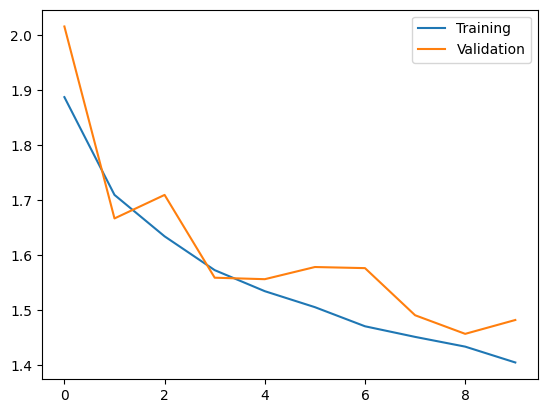

In [30]:
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.legend()
plt.show()

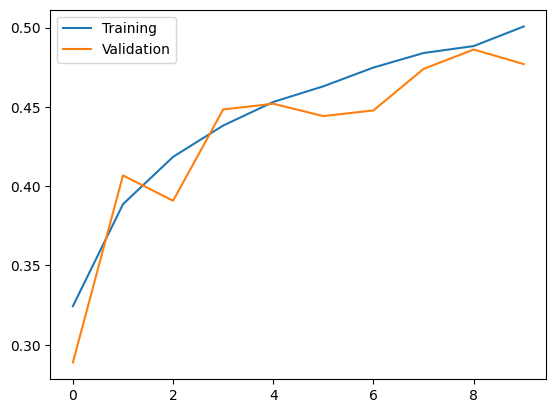

In [31]:
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.legend()
plt.show()